# 00 · Setup: carga dos dados no SQL Server

Este notebook prepara a **fonte relacional** do pipeline: cria o banco `AcademiaDB` no SQL Server 2025
(rodando no Docker), cria as **5 tabelas** com chaves primárias e estrangeiras e carrega os CSVs da pasta `data/`.

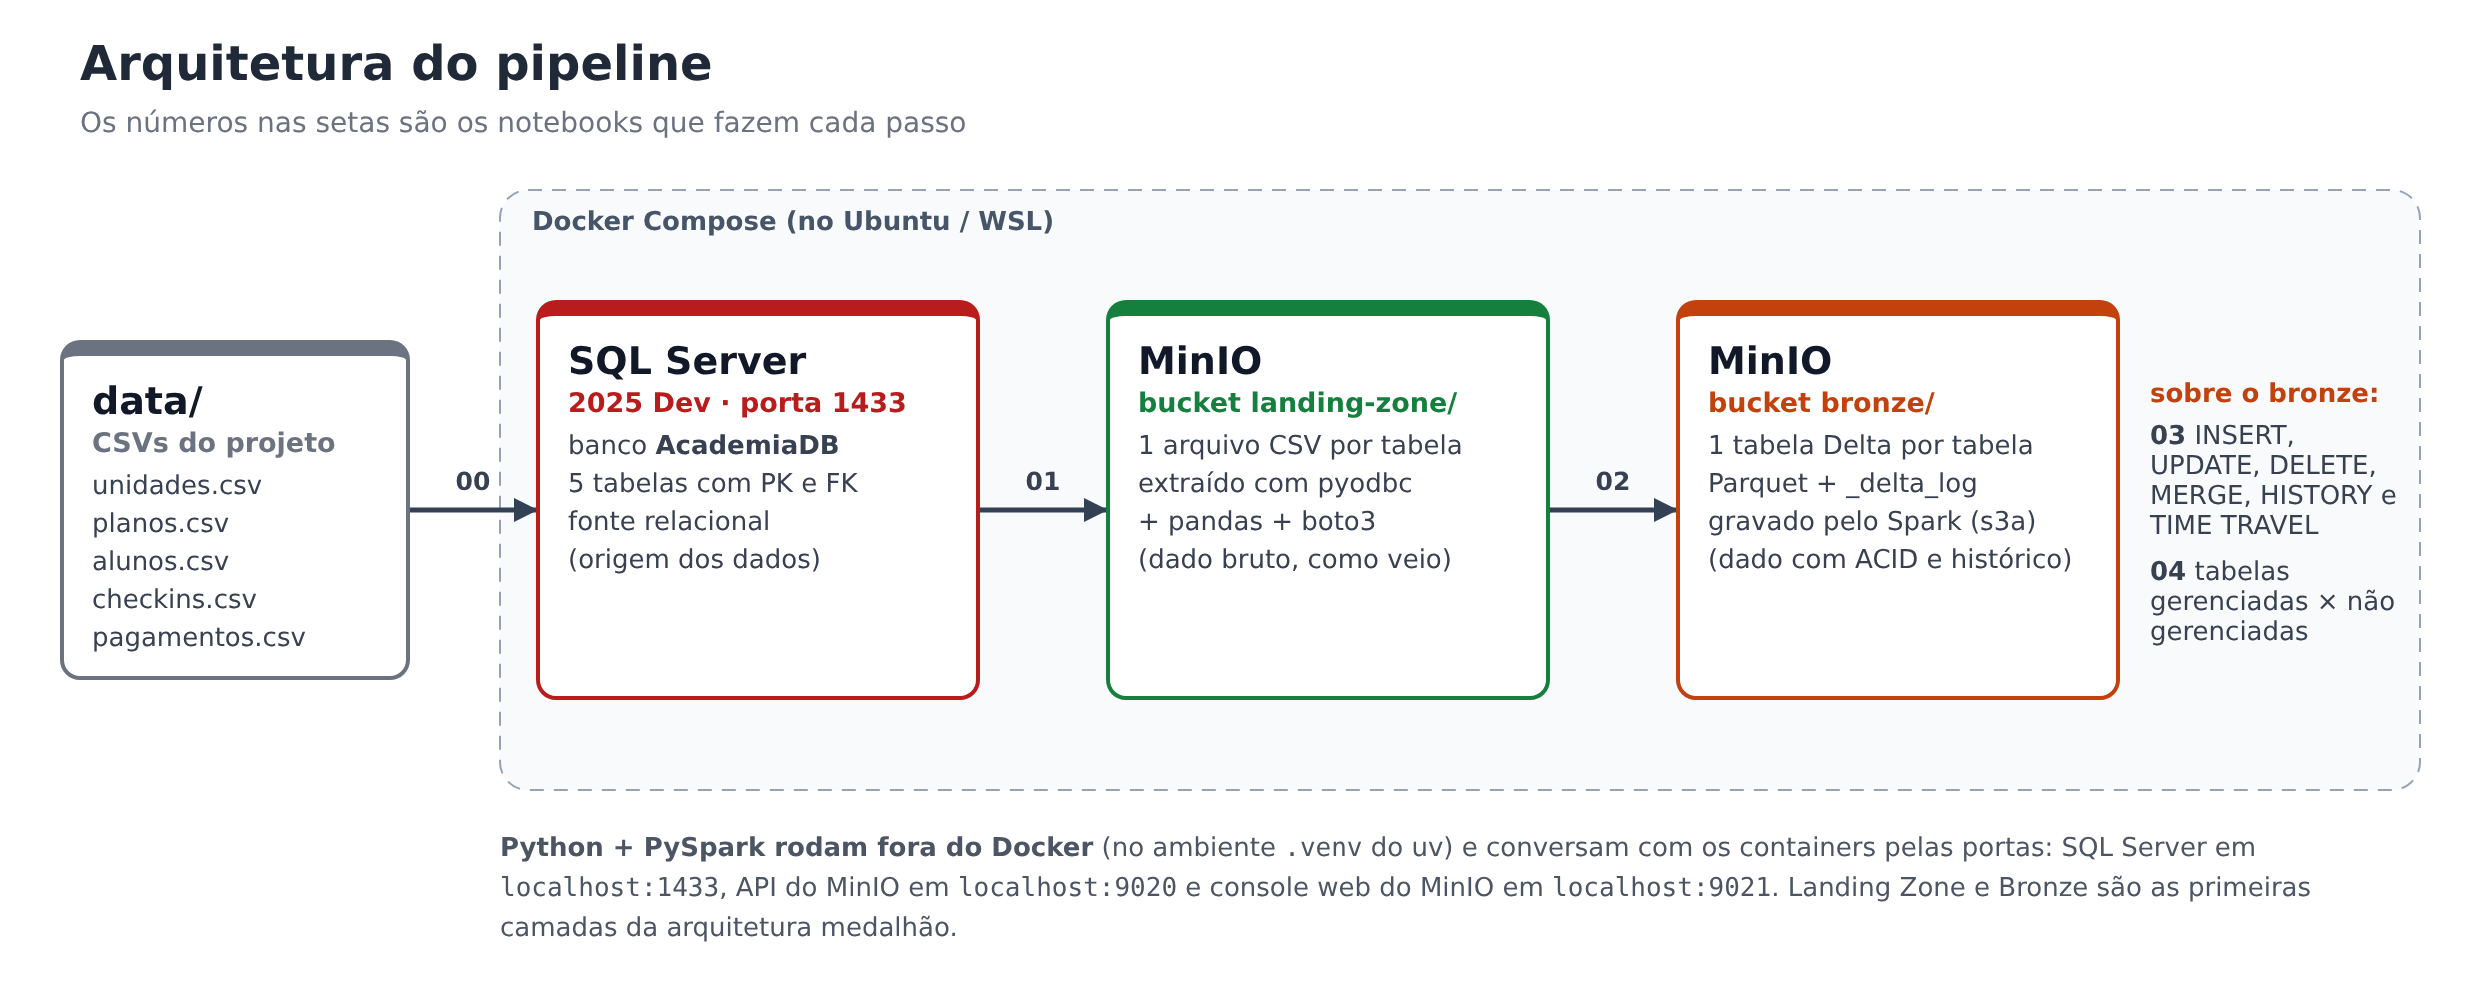

**Antes de rodar:** containers no ar (`docker compose up -d`), arquivo `.env` criado e ODBC Driver 18 instalado.

## 1. Configuração

In [ ]:
import os
from pathlib import Path
from dotenv import load_dotenv

# Raiz do projeto (funciona abrindo o notebook pelo VS Code, pelo JupyterLab ou pelo nbconvert)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / ".env").exists():
    raise FileNotFoundError("Arquivo .env não encontrado. Na raiz do projeto rode: cp .env.example .env")
load_dotenv(ROOT / ".env", override=True)

DB_SERVER   = os.getenv("DB_SERVER")
DB_PORT     = os.getenv("DB_PORT")
DB_USER     = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_DATABASE = os.getenv("DB_DATABASE")

print(f"SQL Server: {DB_SERVER}:{DB_PORT} | Database: {DB_DATABASE}")

In [ ]:
import time
import pyodbc


def conectar(database="master", tentativas=12):
    """Conecta ao SQL Server, tentando de novo enquanto o container ainda está iniciando."""
    conn_str = (
        "DRIVER={ODBC Driver 18 for SQL Server};"
        f"SERVER={DB_SERVER},{DB_PORT};DATABASE={database};"
        f"UID={DB_USER};PWD={DB_PASSWORD};TrustServerCertificate=yes;"
    )
    for i in range(1, tentativas + 1):
        try:
            return pyodbc.connect(conn_str, autocommit=True, timeout=5)
        except pyodbc.Error as erro:
            print(f"Tentativa {i}/{tentativas}: SQL Server ainda não respondeu ({erro.args[0]}). Aguardando 5 s...")
            time.sleep(5)
    raise RuntimeError("Não foi possível conectar ao SQL Server. Confira com: docker compose ps")

## 2. Criar o banco `AcademiaDB`

In [ ]:
conn_master = conectar("master")
conn_master.cursor().execute(f"""
    IF DB_ID('{DB_DATABASE}') IS NULL
        CREATE DATABASE [{DB_DATABASE}]
""")
conn_master.close()

conn = conectar(DB_DATABASE)
cursor = conn.cursor()
print(f"Conectado ao [{DB_DATABASE}]")

## 3. Criar as 5 tabelas

O cenário continua o do Trabalho 1 (academia). Em azul estão as 3 tabelas que já existiam
(`planos`, `alunos`, `checkins`) e em verde as 2 novas (`unidades` e `pagamentos`).

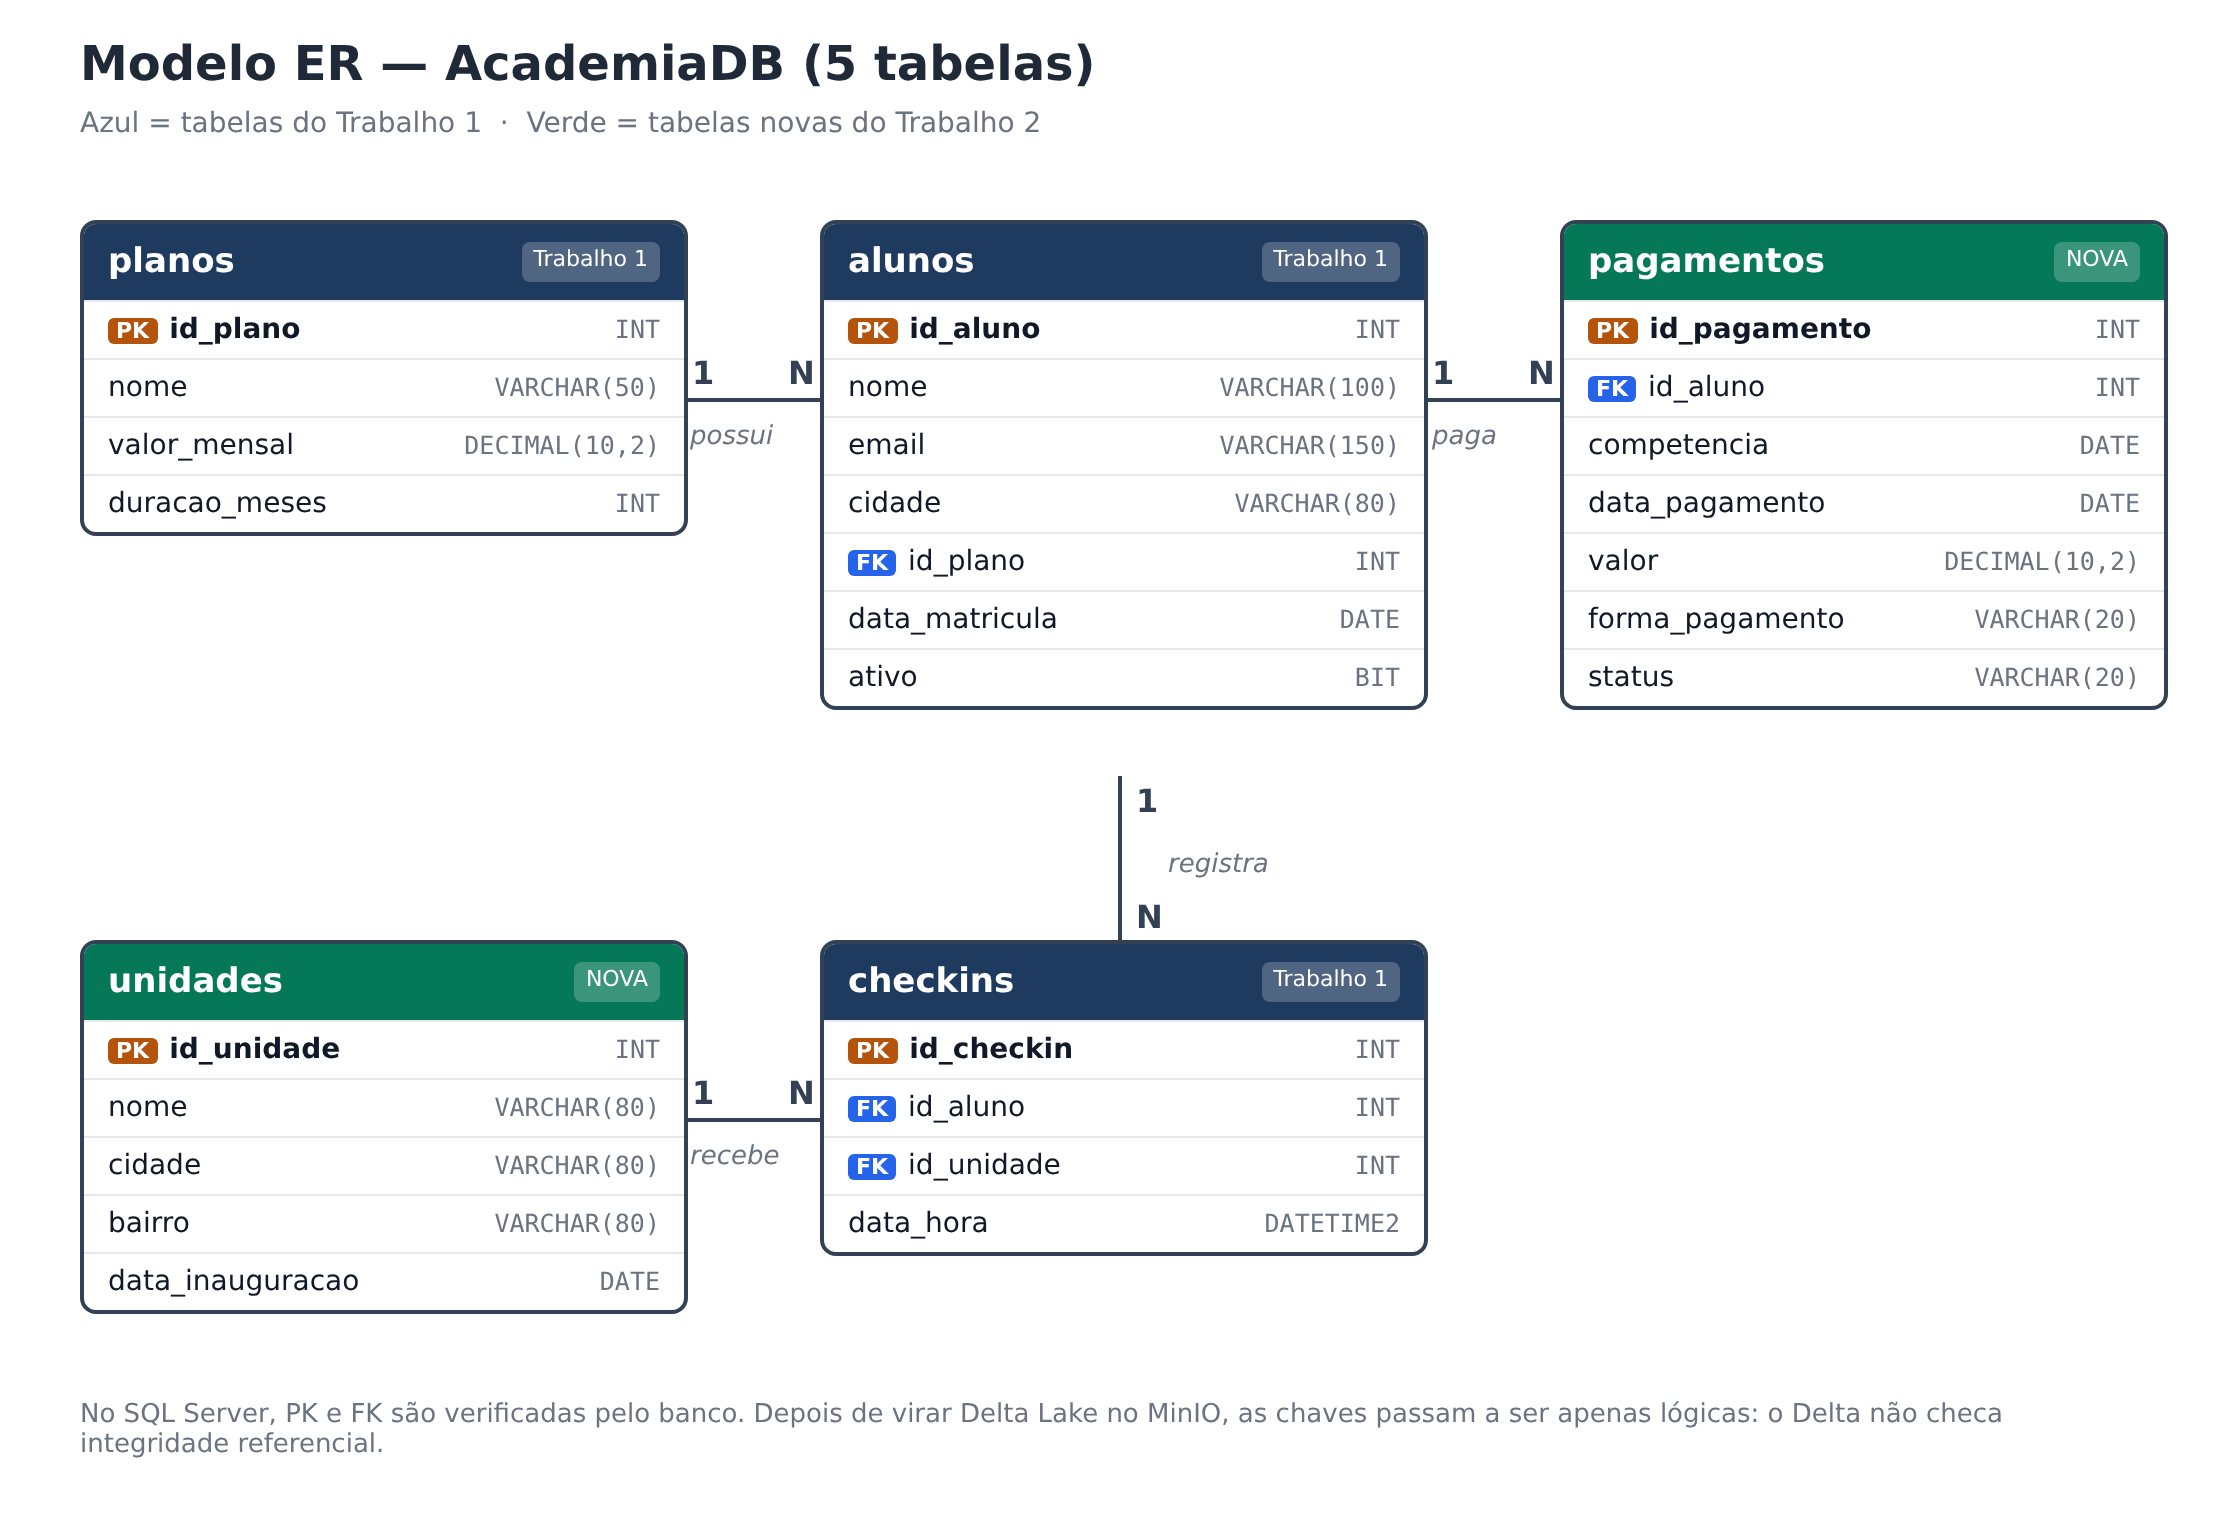

No SQL Server as chaves estrangeiras são **verificadas pelo banco**: por isso as tabelas são criadas e carregadas
na ordem das dependências (primeiro quem é referenciado, depois quem referencia).

> Para recriar tudo do zero (por exemplo, depois de mudar os CSVs), troque `RECRIAR = False` por `True`.

In [ ]:
RECRIAR = False

ORDEM = ["unidades", "planos", "alunos", "checkins", "pagamentos"]   # ordem das dependências

if RECRIAR:
    for tabela in reversed(ORDEM):
        cursor.execute(f"DROP TABLE IF EXISTS dbo.{tabela}")
    print("Tabelas apagadas para recriação.")

In [ ]:
DDL = {
    "unidades": """
        CREATE TABLE dbo.unidades (
            id_unidade        INT          NOT NULL PRIMARY KEY,
            nome              VARCHAR(80)  NOT NULL,
            cidade            VARCHAR(80)  NOT NULL,
            bairro            VARCHAR(80)  NULL,
            data_inauguracao  DATE         NULL
        )""",
    "planos": """
        CREATE TABLE dbo.planos (
            id_plano       INT            NOT NULL PRIMARY KEY,
            nome           VARCHAR(50)    NOT NULL,
            valor_mensal   DECIMAL(10,2)  NOT NULL,
            duracao_meses  INT            NOT NULL
        )""",
    "alunos": """
        CREATE TABLE dbo.alunos (
            id_aluno        INT           NOT NULL PRIMARY KEY,
            nome            VARCHAR(100)  NOT NULL,
            email           VARCHAR(150)  NULL,
            cidade          VARCHAR(80)   NULL,
            id_plano        INT           NOT NULL,
            data_matricula  DATE          NULL,
            ativo           BIT           NOT NULL,
            CONSTRAINT fk_alunos_planos FOREIGN KEY (id_plano) REFERENCES dbo.planos (id_plano)
        )""",
    "checkins": """
        CREATE TABLE dbo.checkins (
            id_checkin  INT           NOT NULL PRIMARY KEY,
            id_aluno    INT           NOT NULL,
            id_unidade  INT           NOT NULL,
            data_hora   DATETIME2(0)  NOT NULL,
            CONSTRAINT fk_checkins_alunos   FOREIGN KEY (id_aluno)   REFERENCES dbo.alunos (id_aluno),
            CONSTRAINT fk_checkins_unidades FOREIGN KEY (id_unidade) REFERENCES dbo.unidades (id_unidade)
        )""",
    "pagamentos": """
        CREATE TABLE dbo.pagamentos (
            id_pagamento     INT            NOT NULL PRIMARY KEY,
            id_aluno         INT            NOT NULL,
            competencia      DATE           NOT NULL,
            data_pagamento   DATE           NULL,
            valor            DECIMAL(10,2)  NOT NULL,
            forma_pagamento  VARCHAR(20)    NULL,
            status           VARCHAR(20)    NOT NULL,
            CONSTRAINT fk_pagamentos_alunos FOREIGN KEY (id_aluno) REFERENCES dbo.alunos (id_aluno)
        )""",
}

for tabela in ORDEM:
    cursor.execute(f"IF OBJECT_ID('dbo.{tabela}', 'U') IS NULL " + DDL[tabela])
    print(f"  tabela {tabela} criada/verificada")

## 4. Carregar os CSVs da pasta `data/`

Os dados são **fictícios e criados pelo grupo** (script `scripts/gerar_dados.py`). Os 5 primeiros alunos,
os 3 primeiros planos e os 8 primeiros check-ins são os mesmos do Trabalho 1, para que os DML do Trabalho 1
possam ser reproduzidos no notebook 03.

Os valores são enviados como texto e o próprio SQL Server converte para INT, DATE, DECIMAL e BIT.
Se a tabela já tiver dados, ela é pulada (o notebook pode ser rodado de novo sem duplicar nada).

In [ ]:
import pandas as pd

DATA_DIR = ROOT / "data"

for tabela in ORDEM:
    cursor.execute(f"SELECT COUNT(*) FROM dbo.{tabela}")
    existentes = cursor.fetchone()[0]
    if existentes > 0:
        print(f"  {tabela:<11} já tem {existentes} registros, pulando")
        continue

    df = pd.read_csv(DATA_DIR / f"{tabela}.csv", dtype=str, keep_default_na=False, encoding="utf-8")
    colunas = ", ".join(df.columns)
    marcadores = ", ".join("?" for _ in df.columns)
    sql = f"INSERT INTO dbo.{tabela} ({colunas}) VALUES ({marcadores})"
    linhas = [tuple(v if v != "" else None for v in linha) for linha in df.itertuples(index=False)]

    for i in range(0, len(linhas), 2000):           # envia em lotes de 2000 linhas
        cursor.executemany(sql, linhas[i:i + 2000])
    print(f"  {tabela:<11} {len(linhas):>6} registros inseridos")

## 5. Validação

In [ ]:
esperado = {t: len(pd.read_csv(DATA_DIR / f"{t}.csv")) for t in ORDEM}

print(f"{'Tabela':<12}{'SQL Server':>12}{'CSV':>8}")
for tabela in ORDEM:
    cursor.execute(f"SELECT COUNT(*) FROM dbo.{tabela}")
    total = cursor.fetchone()[0]
    print(f"{tabela:<12}{total:>12}{esperado[tabela]:>8}")
    assert total == esperado[tabela], f"{tabela}: quantidade diferente do CSV"

print("\nOK: todas as tabelas batem com os CSVs.")

In [ ]:
# As chaves estrangeiras estão valendo: o SQL Server recusa um check-in de um aluno que não existe
try:
    cursor.execute("INSERT INTO dbo.checkins VALUES (999999, 999999, 1, '2024-06-01 08:00:00')")
except pyodbc.Error as erro:
    print("O SQL Server recusou, como esperado:\n", str(erro.args[1])[:160], "...")

In [ ]:
cursor.execute("SELECT TOP 5 * FROM dbo.alunos ORDER BY id_aluno")
print([c[0] for c in cursor.description])
for linha in cursor.fetchall():
    print(tuple(linha))

In [ ]:
cursor.close()
conn.close()
print("Conexão encerrada.")